<a href="https://colab.research.google.com/github/rohit-jain8/Problem-Set-1/blob/main/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

Household: I'm focusing on a single parent with one child living in the Boston area who works a full-time hourly job. The household rents an apartment, cooks most meals at home, and relies on a used car to commute to work and get around. I chose this household because a large portion of its income goes toward necessities like rent, groceries, transportation, utilities, and healthcare. As a result, increases in these prices can have a pretty significant impact on the household's overall cost of living.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [71]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent", "Price_2019": 1800, "Price_2024": 2400, "weight": 0.40},
    {"Item": "Food at Home", "Price_2019": 500, "Price_2024": 625, "weight": 0.20},
    {"Item": "Used Car", "Price_2019": 15000, "Price_2024": 19500, "weight": 0.10},
    {"Item": "Gasoline", "Price_2019": 2.60, "Price_2024": 3.30, "weight": 0.08},
    {"Item": "Utilities", "Price_2019": 200, "Price_2024": 250, "weight": 0.12},
    {"Item": "Healthcare", "Price_2019": 300, "Price_2024": 360, "weight": 0.10}
]

In [72]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [73]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    index = 0

    for item in basket:
        price_ratio = item[current_key] / item[base_key]
        weighted_ratio = price_ratio * item["weight"]
        index = index + weighted_ratio

    return index * 100

In [74]:
# 1. the unweighted average price change across categories
total_change = 0

for item in household_basket:
    change = (item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100
    total_change = total_change + change

unweighted_average = total_change / len(household_basket)

print(f"Unweighted average price change: {unweighted_average:.2f}%")

# 2. your weighted Laspeyres index
weighted_index = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted_change = weighted_index - 100

print(f"Weighted Laspeyres index: {weighted_index:.2f}")
print(f"Weighted price change: {weighted_change:.2f}%")

# 3. the gap between them
gap = weighted_change - unweighted_average

print(f"Gap: {gap:.2f} percentage points")

Unweighted average price change: 26.71%
Weighted Laspeyres index: 128.49
Weighted price change: 28.49%
Gap: 1.78 percentage points


**Why do the two differ, and which would you defend to the client?**

The unweighted average shows that prices across the six categories increased by 26.71% between 2019 and 2024, while my weighted Laspeyres index shows an increase of 28.49%. That's a difference of 1.78 percentage points. The reason they differ is that the unweighted average treats every category equally, while the weighted index takes into account how much of the household's spending goes toward each category. For example, rent makes up 40% of this household's spending, so an increase in rent has a much bigger impact than an increase in a category with a smaller weight. I would use the weighted index when presenting these findings to the client because it gives a more realistic picture of how rising prices affect this particular household.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [75]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

fred_data = {}

for series in series_ids:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    data = pd.read_csv(url)
    fred_data[series] = data

for series in series_ids:
    print(series)
    print(fred_data[series].head())

CPIAUCSL
  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95
CUSR0000SEHA
  observation_date  CUSR0000SEHA
0       1981-01-01          84.7
1       1981-02-01          85.2
2       1981-03-01          85.9
3       1981-04-01          86.5
4       1981-05-01          87.1
CUSR0000SAF11
  observation_date  CUSR0000SAF11
0       1952-01-01           31.2
1       1952-02-01           30.7
2       1952-03-01           30.7
3       1952-04-01           30.8
4       1952-05-01           30.8
CUSR0000SETA02
  observation_date  CUSR0000SETA02
0       1953-01-01            28.7
1       1953-02-01            28.7
2       1953-03-01            28.4
3       1953-04-01            28.3
4       1953-05-01            27.5


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | This gives me an overall inflation benchmark to compare against my household's cost of living. | It represents spending across the country, so it doesn't necessarily reflect how this particular household spends its money. |
| `CUSR0000SEHA` | Rent is the household's largest expense, making this a useful measure of how housing costs have changed. | It measures rent across the U.S., so it might not fully reflect what a household in Boston is experiencing. |
| `CUSR0000SAF11` | Since this household cooks most of its meals at home, this is a good way to track changes in grocery prices. | It covers a broad range of groceries and might not match the specific foods or brands this household buys. |
| `CUSR0000SETA02` | The household relies on a used car for transportation, so this helps measure changes in an important transportation expense. | It only measures used vehicle prices and doesn't include expenses like gas, insurance, maintenance, or repairs. |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [76]:
# Rebase to 2019 = 100

for series in series_ids:
    data = fred_data[series]
    data["observation_date"] = pd.to_datetime(data["observation_date"])

    data_2019 = data[
        data["observation_date"].dt.year == 2019
    ]

    base_value = data_2019[series].mean()
    data["Rebased"] = data[series] / base_value * 100

    data_2024 = data[
        data["observation_date"].dt.year == 2024
    ]

    average_2024 = data_2024["Rebased"].mean()

    print(series, "2024 average index:", round(average_2024, 2))

CPIAUCSL 2024 average index: 122.7
CUSR0000SEHA 2024 average index: 126.86
CUSR0000SAF11 2024 average index: 126.8
CUSR0000SETA02 2024 average index: 128.7


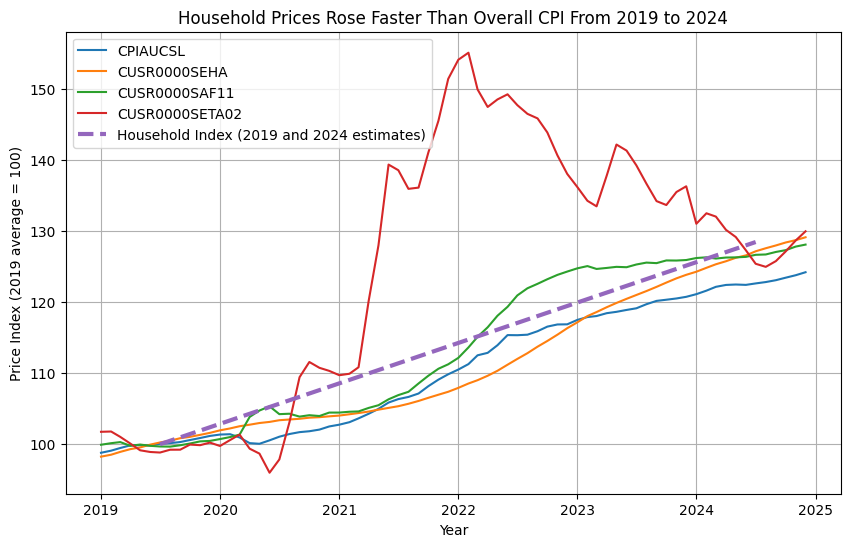

In [77]:
# One chart: every rebased series, plus your household index


# Plot the rebased FRED series and the household index

plt.figure(figsize=(10, 6))

for series in series_ids:
    data = fred_data[series]

    data_2019_2024 = data[
        (data["observation_date"] >= "2019-01-01") &
        (data["observation_date"] <= "2024-12-01")
    ]

    plt.plot(
        data_2019_2024["observation_date"],
        data_2019_2024["Rebased"],
        label=series
    )

household_dates = pd.to_datetime(["2019-07-01", "2024-07-01"])
household_values = [100, weighted_index]

plt.plot(
    household_dates,
    household_values,
    label="Household Index (2019 and 2024 estimates)",
    linewidth=3,
    linestyle="--"
)

plt.xlabel("Year")
plt.ylabel("Price Index (2019 average = 100)")
plt.title("Household Prices Rose Faster Than Overall CPI From 2019 to 2024")
plt.legend()
plt.grid(True)
plt.show()

Between 2019 and 2024, my household's price index increased by 28.49%, compared to 22.70% for overall CPI. This is a difference of 5.79 percentage points, suggesting that this household experienced greater price increases than the national average. It's also important to note that my household index only uses estimated prices from 2019 and 2024, so the dashed line shows the overall change between those years rather than actual monthly price movements.

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. If the count is zero, report
> zero.

In [78]:
# First observation, last observation, frequency and missing months, for every series

for series in series_ids:
    data = fred_data[series]

    data = data.set_index("observation_date")
    monthly_data = data[series].asfreq("MS")

    first_date = monthly_data.index.min()
    last_date = monthly_data.index.max()
    missing_months = monthly_data.isna().sum()

    print("Series:", series)
    print("First observation:", first_date)
    print("Last observation:", last_date)
    print("Frequency: Monthly")
    print("Missing months:", missing_months)
    print()

# Check October 2025 observations

for series in series_ids:
    data = fred_data[series]

    october_data = data[
        data["observation_date"] == "2025-10-01"
    ]

    print(series)
    print(october_data[["observation_date", series]])
    print()


Series: CPIAUCSL
First observation: 1947-01-01 00:00:00
Last observation: 2026-08-01 00:00:00
Frequency: Monthly
Missing months: 1

Series: CUSR0000SEHA
First observation: 1981-01-01 00:00:00
Last observation: 2026-08-01 00:00:00
Frequency: Monthly
Missing months: 1

Series: CUSR0000SAF11
First observation: 1952-01-01 00:00:00
Last observation: 2026-08-01 00:00:00
Frequency: Monthly
Missing months: 1

Series: CUSR0000SETA02
First observation: 1953-01-01 00:00:00
Last observation: 2026-08-01 00:00:00
Frequency: Monthly
Missing months: 0

CPIAUCSL
    observation_date  CPIAUCSL
945       2025-10-01       NaN

CUSR0000SEHA
    observation_date  CUSR0000SEHA
537       2025-10-01           NaN

CUSR0000SAF11
    observation_date  CUSR0000SAF11
885       2025-10-01            NaN

CUSR0000SETA02
    observation_date  CUSR0000SETA02
873       2025-10-01         186.111



| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| CPIAUCSL | 1947-01-01 | 2026-08-01 | Monthly | 1 |
| CUSR0000SEHA | 1981-01-01 | 2026-08-01 | Monthly | 1 |
| CUSR0000SAF11 | 1952-01-01 | 2026-08-01 | Monthly | 1 |
| CUSR0000SETA02 | 1953-01-01 | 2026-08-01 | Monthly | 0 |

Three of the four FRED series are missing an observation for October 2025 because of the federal government shutdown, which disrupted CPI data collection. The Used Cars series is the only one without any missing months. I'm going to leave these observations missing rather than estimate values that weren't reported. Since my main comparison focuses on 2019 through 2024, these missing values don't affect my results. However, if I were analyzing October 2025 specifically, I would exclude the missing observations rather than treat them as zero.

Source: [Bureau of Labor Statistics — 2025 Government Shutdown and CPI](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm)

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [79]:
# Start dates side by side, and the common sample

start_dates = []
end_dates = []

for series in series_ids:
    data = fred_data[series]

    first_date = data["observation_date"].min()
    last_date = data["observation_date"].max()

    print(series, "starts:", first_date)

    start_dates.append(first_date)
    end_dates.append(last_date)

common_start = max(start_dates)
common_end = min(end_dates)

print()
print("Common sample starts:", common_start)
print("Common sample ends:", common_end)

common_months = 0

for date in fred_data["CPIAUCSL"]["observation_date"]:
    if date >= common_start and date <= common_end:
        common_months = common_months + 1

longest_months = len(fred_data["CPIAUCSL"])
discarded_months = longest_months - common_months

print("Common sample months:", common_months)
print("Months discarded from longest series:", discarded_months)

# Check how many observations are available in the common sample

for series in series_ids:
    data = fred_data[series]

    common_data = data[
        (data["observation_date"] >= common_start) &
        (data["observation_date"] <= common_end)
    ]

    available_months = common_data[series].count()

    print(series, "available observations:", available_months)

CPIAUCSL starts: 1947-01-01 00:00:00
CUSR0000SEHA starts: 1981-01-01 00:00:00
CUSR0000SAF11 starts: 1952-01-01 00:00:00
CUSR0000SETA02 starts: 1953-01-01 00:00:00

Common sample starts: 1981-01-01 00:00:00
Common sample ends: 2026-08-01 00:00:00
Common sample months: 548
Months discarded from longest series: 408
CPIAUCSL available observations: 547
CUSR0000SEHA available observations: 547
CUSR0000SAF11 available observations: 547
CUSR0000SETA02 available observations: 548


In [80]:

# Headline comparison: full history vs common sample

for series in series_ids:
    data = fred_data[series]

    # Calculate price change over the full history
    full_start = data[series].iloc[0]
    full_end = data[series].iloc[-1]

    full_change = (full_end - full_start) / full_start * 100

    # Restrict the data to the common sample
    common_data = data[
        (data["observation_date"] >= common_start) &
        (data["observation_date"] <= common_end)
    ]

    # Calculate price change over the common sample
    common_first = common_data[series].iloc[0]
    common_last = common_data[series].iloc[-1]

    common_change = (common_last - common_first) / common_first * 100

    # Calculate the difference between the two results
    difference = full_change - common_change

    # Print the results
    print("Series:", series)
    print(f"Full history price change: {full_change:.2f}%")
    print(f"Common sample price change: {common_change:.2f}%")
    print(f"Difference: {difference:.2f} percentage points")
    print()

Series: CPIAUCSL
Full history price change: 1455.54%
Common sample price change: 283.18%
Difference: 1172.37 percentage points

Series: CUSR0000SEHA
Full history price change: 430.49%
Common sample price change: 430.49%
Difference: 0.00 percentage points

Series: CUSR0000SAF11
Full history price change: 929.92%
Common sample price change: 244.04%
Difference: 685.88 percentage points

Series: CUSR0000SETA02
Full history price change: 530.54%
Common sample price change: 157.42%
Difference: 373.12 percentage points



**What restricting to the common sample assumes, and what not restricting assumes:**

Using a common sample means I'm prioritizing a fair comparison across all four series rather than using every observation available. Since Rent only goes back to January 1981, restricting the data means comparing everything from January 1981 through August 2026. The benefit is that all four series cover the same period, but the downside is that we're leaving out older data that could still be useful. On the other hand, using each series' full history gives us more information, but it can be misleading to compare price changes when the starting dates are different.

For example, overall CPI increased by 1,455.54% over its full history, compared to 283.18% over the common sample, a difference of 1,172.37 percentage points. Rent increased by 430.49% in both cases because its data already starts in January 1981. I would use the common-sample results when comparing these categories for the client because they provide a more consistent comparison. However, since the client's main concern is how prices changed between 2019 and 2024, I would focus on that shorter period when making my final recommendation.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

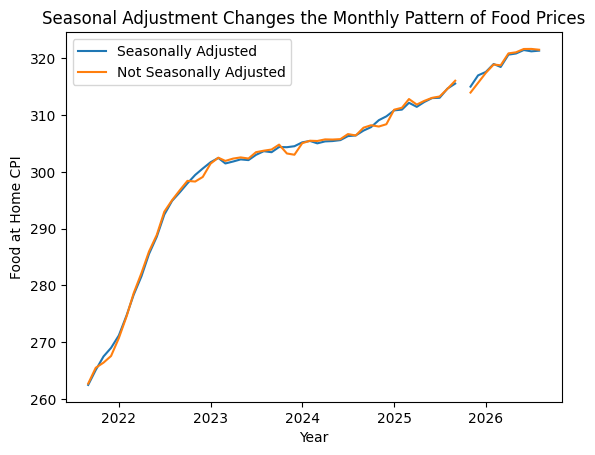

In [81]:
# Seasonally adjusted vs unadjusted, last five years

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CUUR0000SAF11"
unadjusted_data = pd.read_csv(url)

unadjusted_data["observation_date"] = pd.to_datetime(unadjusted_data["observation_date"])

adjusted_data = fred_data["CUSR0000SAF11"]

adjusted_5years = adjusted_data[
    (adjusted_data["observation_date"] >= "2021-09-01") &
    (adjusted_data["observation_date"] <= "2026-08-01")
]

unadjusted_5years = unadjusted_data[
    (unadjusted_data["observation_date"] >= "2021-09-01") &
    (unadjusted_data["observation_date"] <= "2026-08-01")
]

plt.plot(adjusted_5years["observation_date"],
         adjusted_5years["CUSR0000SAF11"],
         label="Seasonally Adjusted")

plt.plot(unadjusted_5years["observation_date"],
         unadjusted_5years["CUUR0000SAF11"],
         label="Not Seasonally Adjusted")

plt.xlabel("Year")
plt.ylabel("Food at Home CPI")
plt.title("Seasonal Adjustment Changes the Monthly Pattern of Food Prices")
plt.legend()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The difference between the two lines comes from seasonal adjustments, which are meant to remove price changes that regularly happen at certain times of the year. Looking at the graph, both series follow almost the same overall trend, but there are some small differences from month to month. The unadjusted series shows the actual reported price movements, including seasonal changes, while the adjusted series makes it easier to see the broader trend without those regular fluctuations.

For this analysis, I would use the seasonally adjusted series because I'm more interested in how food prices have changed over time than in short-term seasonal movements. It also keeps my comparison consistent with the other FRED series I'm using. However, if the client wanted to know what workers were actually paying in a particular month, I would use the unadjusted series since those seasonal price changes still affect their expenses.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

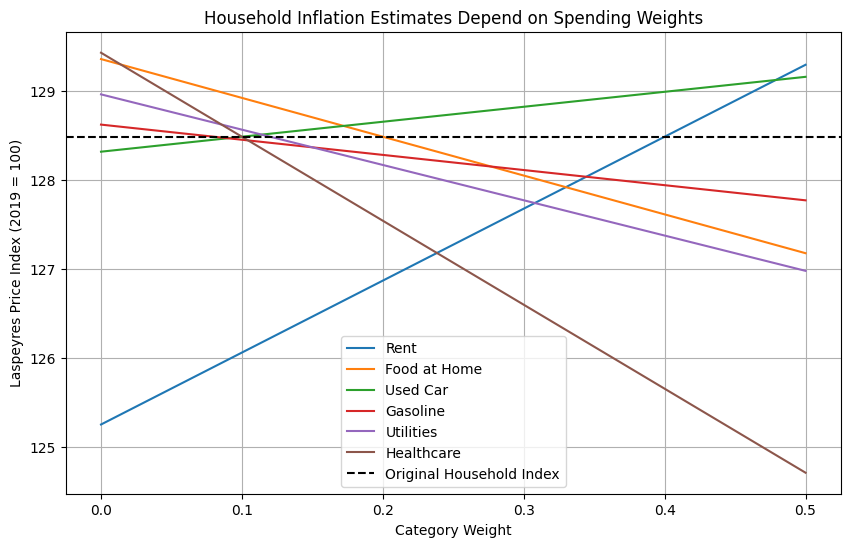

Rent Index range: 4.04
Food at Home Index range: 2.18
Used Car Index range: 0.84
Gasoline Index range: 0.85
Utilities Index range: 1.98
Healthcare Index range: 4.72

Most sensitive category: Healthcare
Largest index change: 4.72


In [82]:
# Paste the AI's code here, run it, and correct it where it is wrong

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the weighted Laspeyres price index
def laspeyres(basket):
    index = 0

    for item in basket:
        price_ratio = item["Price_2024"] / item["Price_2019"]
        index = index + price_ratio * item["weight"]

    return index * 100

# Calculate the original household index
original_index = laspeyres(household_basket)

# Test weights from 0% to 50%
test_weights = np.linspace(0, 0.5, 51)

# Store the sensitivity results
sensitivity_results = {}

for category in household_basket:

    category_name = category["Item"]
    results = []

    for new_weight in test_weights:

        adjusted_basket = []

        # Find the total weight of the other categories
        other_weight = 1 - category["weight"]

        for item in household_basket:

            if item["Item"] == category_name:
                adjusted_weight = new_weight

            else:
                # Adjust other weights proportionally.
                # This keeps their relative spending shares unchanged
                # while ensuring all weights still sum to 1.
                adjusted_weight = (
                    item["weight"] / other_weight
                ) * (1 - new_weight)

            adjusted_basket.append({
                "Item": item["Item"],
                "Price_2019": item["Price_2019"],
                "Price_2024": item["Price_2024"],
                "weight": adjusted_weight
            })

        new_index = laspeyres(adjusted_basket)
        results.append(new_index)

    sensitivity_results[category_name] = results


# Plot all six sensitivity curves
plt.figure(figsize=(10, 6))

for category_name in sensitivity_results:
    plt.plot(
        test_weights,
        sensitivity_results[category_name],
        label=category_name
    )

plt.axhline(
    y=original_index,
    color="black",
    linestyle="--",
    label="Original Household Index"
)

plt.xlabel("Category Weight")
plt.ylabel("Laspeyres Price Index (2019 = 100)")
plt.title("Household Inflation Estimates Depend on Spending Weights")
plt.legend()
plt.grid(True)
plt.show()

# Compare the total change in the index for each category
largest_change = 0
most_sensitive = ""

for category_name in sensitivity_results:

    results = sensitivity_results[category_name]
    index_change = abs(results[-1] - results[0])

    print(category_name, "Index range:", round(index_change, 2))

    if index_change > largest_change:
        largest_change = index_change
        most_sensitive = category_name

print()
print("Most sensitive category:", most_sensitive)
print("Largest index change:", round(largest_change, 2))

**What did the model get wrong, or get right in a way you had to check? Show the check.**

In [83]:

# Verify the AI sensitivity analysis

# Check the original household weights
total_weight = sum(item["weight"] for item in household_basket)
print("Original weights sum to:", round(total_weight, 2))

# Check the original household index
print("Original index:", round(original_index, 2))

# Check that the adjusted weights sum to 1
for category in household_basket:
    category_name = category["Item"]
    original_weight = category["weight"]

    # Test the adjusted weights at 0% and 50%
    for new_weight in [0, 0.5]:
        adjusted_total = 0

        for item in household_basket:
            if item["Item"] == category_name:
                adjusted_weight = new_weight
            else:
                adjusted_weight = (
                    item["weight"] / (1 - original_weight)
                ) * (1 - new_weight)

            adjusted_total += adjusted_weight

        print(
            category_name,
            "weight =", new_weight,
            "total =", round(adjusted_total, 2)
        )

# Check which category has the largest index change
largest_change = 0
most_sensitive = ""

for category_name in sensitivity_results:
    results = sensitivity_results[category_name]
    index_change = abs(results[-1] - results[0])

    print(category_name, "Index change:", round(index_change, 2))

    if index_change > largest_change:
        largest_change = index_change
        most_sensitive = category_name

print("Most sensitive category:", most_sensitive)
print("Largest index change:", round(largest_change, 2))

Original weights sum to: 1.0
Original index: 128.49
Rent weight = 0 total = 1.0
Rent weight = 0.5 total = 1.0
Food at Home weight = 0 total = 1.0
Food at Home weight = 0.5 total = 1.0
Used Car weight = 0 total = 1.0
Used Car weight = 0.5 total = 1.0
Gasoline weight = 0 total = 1.0
Gasoline weight = 0.5 total = 1.0
Utilities weight = 0 total = 1.0
Utilities weight = 0.5 total = 1.0
Healthcare weight = 0 total = 1.0
Healthcare weight = 0.5 total = 1.0
Rent Index change: 4.04
Food at Home Index change: 2.18
Used Car Index change: 0.84
Gasoline Index change: 0.85
Utilities Index change: 1.98
Healthcare Index change: 4.72
Most sensitive category: Healthcare
Largest index change: 4.72


The AI did a good job generating the sensitivity analysis, but I wanted to make sure the calculations were actually correct rather than just assuming they were. I started by checking that my original spending weights added up to 1.0 and that the household index was still 128.49, which matched my earlier results.

I then tested the adjusted weights at both 0% and 50% for every category to make sure the total always remained 1.0. After that, I compared how much the index changed for each category. Healthcare had the largest change at 4.72 points, followed by Rent at 4.04 points. All of these checks matched the results from the AI-generated analysis.

One thing I found interesting was that Rent had the largest original spending weight, but Healthcare was actually the category the index was most sensitive to. This shows that the overall inflation estimate depends on more than just which category takes up the most spending. For the client, I would emphasize that changes in spending patterns can affect the inflation rate a household experiences, which is why it's important to consider the household's actual expenses.

### AI Transcript

**Model:** GPT-6&nbsp; **Date:** October 9, 2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

Prompt: [Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

Response: Household Laspeyres Index: Weight Sensitivity Analysis
The following Python code performs a sensitivity analysis on your household price index. It varies each spending category's weight from 0% to 50%, proportionally adjusts the remaining categories' weights so they continue to sum to 100%, and recalculates the Laspeyres price index.
The resulting chart shows how sensitive the overall index is to changes in each category's spending weight.
1. Python code
The code assumes household_basket already exists and contains six dictionaries with the keys Item, Price_2019, Price_2024, and weight.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the weighted Laspeyres price index
def laspeyres(basket):
    index = 0

    for item in basket:
        price_ratio = item["Price_2024"] / item["Price_2019"]
        index = index + price_ratio * item["weight"]

    return index * 100

# Calculate the original household index
original_index = laspeyres(household_basket)

# Test weights from 0% to 50%
test_weights = np.linspace(0, 0.5, 51)

# Store the sensitivity results
sensitivity_results = {}

for category in household_basket:

    category_name = category["Item"]
    results = []

    for new_weight in test_weights:

        adjusted_basket = []

        # Find the total weight of the other categories
        other_weight = 1 - category["weight"]

        for item in household_basket:

            if item["Item"] == category_name:
                adjusted_weight = new_weight

            else:
                # Adjust other weights proportionally.
                # This keeps their relative spending shares unchanged
                # while ensuring all weights still sum to 1.
                adjusted_weight = (
                    item["weight"] / other_weight
                ) * (1 - new_weight)

            adjusted_basket.append({
                "Item": item["Item"],
                "Price_2019": item["Price_2019"],
                "Price_2024": item["Price_2024"],
                "weight": adjusted_weight
            })

        new_index = laspeyres(adjusted_basket)
        results.append(new_index)

    sensitivity_results[category_name] = results


# Plot all six sensitivity curves
plt.figure(figsize=(10, 6))

for category_name in sensitivity_results:
    plt.plot(
        test_weights,
        sensitivity_results[category_name],
        label=category_name
    )

plt.axhline(
    y=original_index,
    color="black",
    linestyle="--",
    label="Original Household Index"
)

plt.xlabel("Category Weight")
plt.ylabel("Laspeyres Price Index (2019 = 100)")
plt.title("Household Inflation Estimates Depend on Spending Weights")
plt.legend()
plt.grid(True)
plt.show()

2. How the sensitivity analysis works
The weighted Laspeyres index is calculated as:
\[
L=100\sum_{i=1}^{6}w_i\frac{P_{i,2024}}{P_{i,2019}}
\]

where \(w_i\) represents the spending weight assigned to category \(i\).
When we change one category's weight, the other weights must change as well. Otherwise, the total spending weights would no longer equal 100%, making the resulting index inconsistent with the original calculation.
For example, suppose rent originally represents 40% of spending. If we increase its weight to 50%, the other categories must collectively decrease from 60% to 50%.
The code accomplishes this using:
\[
w_{j,\text{new}}=
\frac{w_{j,\text{original}}}{1-w_{i,\text{original}}}
(1-w_{i,\text{new}})
\]

This preserves the relative proportions of the other five categories while keeping the total weight equal to 1.
3. How to identify the most influential category
Each line on the chart represents one spending category.
A steeper line indicates greater sensitivity: changing that category's weight produces a larger change in the overall household price index.
A relatively flat line indicates that changing the category's weight has little effect on the result.
To identify the most influential category numerically, add:

# Compare the total change in the index for each category
largest_change = 0
most_sensitive = ""

for category_name in sensitivity_results:

    results = sensitivity_results[category_name]
    index_change = abs(results[-1] - results[0])

    print(category_name, "Index range:", round(index_change, 2))

    if index_change > largest_change:
        largest_change = index_change
        most_sensitive = category_name

print()
print("Most sensitive category:", most_sensitive)
print("Largest index change:", round(largest_change, 2))

This measures the absolute difference between the index calculated at a 0% weight and the index calculated at a 50% weight.
4. Which category dominates the result?
The dominant category cannot be identified definitively without the actual values in household_basket.
The answer depends on both the price changes in each category and how those price changes compare with the other categories.
Importantly, the category with the largest original spending weight is not necessarily the most sensitive category.
For example, a category with a relatively small spending weight but unusually large price increases could have a substantial effect on the overall index if its weight were increased.
The additional code above will identify the category producing the largest index change across the tested weight range.
5. What to communicate to a client
The key message is that a household-specific inflation estimate depends not only on how much prices have increased, but also on how household spending is distributed across categories.
A suitable client-facing interpretation would be:
Our sensitivity analysis shows how changes in household spending patterns can affect the estimated cost-of-living increase. Categories with steeper sensitivity curves have a greater influence on the overall index, meaning households that spend more heavily on those categories may experience inflation differently. The results should therefore be interpreted in the context of the household's actual spending patterns rather than treated as a universal inflation measure.

Once the code is run, this explanation should be updated to name the most sensitive category and quantify how much the index changes when its weight varies from 0% to 50%.
Recommendation: Report the original Laspeyres index alongside the sensitivity chart and the most sensitive category's index range. Together, these provide a more transparent assessment of how robust the household inflation estimate is to assumptions about spending weights.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

To: Director, Policy & Insights

Our household's estimated cost of living increased by 28.49% between 2019 and 2024, compared to a 22.70% increase in overall CPI. That's a difference of 5.79 percentage points, suggesting that CPI may actually understate the price increases this particular household is facing.

A big reason for this difference is how the household spends its money. Rent and groceries make up a large portion of its monthly expenses, so increases in these prices have a greater impact on its overall cost of living. I also found that Healthcare was the most sensitive category in my analysis. When I adjusted its spending weight between 0% and 50%, the household index changed by 4.72 points, compared to 4.04 points for Rent.

I have moderate confidence in these findings. I verified the calculations and used official CPI data from FRED, but the household's prices and spending weights are estimates. This means the results give us a useful example of how inflation can affect households differently, but they don't necessarily represent what every worker is experiencing. The comparison also uses annual average CPI data rather than identical monthly household observations.

Based on these results, I would recommend that the client consider its employees' actual spending patterns alongside national CPI when deciding whether to increase starting wages.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1` on GitHub